# Does CVSS tell us what to patch?

This notebook tests whether CVSS base scores help decide which vulnerabilities to patch first, using SQL on `data/processed/cves.duckdb` (built by `src/build_dataset.py`).

- **Universe:** CVEs published in NVD from 2022-01-01 to 2024-12-31 (UTC day), excluding *Rejected* ones.
- **Severity:** CVSS v3.1 base score, or v3.0 if there is no v3.1. Critical ≥ 9.0, High 7.0–8.9, Medium 4.0–6.9, Low < 4.0; CVEs without a CVSS v3 score are kept as *Unscored*.
- **Exploited (main metric):** added to the CISA Known Exploited Vulnerabilities (KEV) catalog no later than 365 days after NVD publication. Sensitivity check: in KEV at any time.
- **Snapshot:** KEV and NVD change over time; the download date of each source is printed below.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

# The kernel starts in notebooks/ (VS Code and nbclient): walk up to the project root.
PROJECT_ROOT = next(folder for folder in (Path.cwd(), *Path.cwd().parents) if (folder / "pyproject.toml").exists())
SRC_DIR = str(PROJECT_ROOT / "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)  # explicit, so the import does not depend on how .venv was installed

# Same definitions as the build, so the analysis cannot drift from them.
from build_dataset import DATABASE, EXPLOITED_WINDOW, SEVERITY_ORDER, pct

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
OVERWRITE_FIGURES = False  # False: keep a figure that already exists (CLAUDE.md idempotence rule)
THRESHOLDS = [9.0, 8.0, 7.0, 6.0, 5.0, 4.0]  # CVSS thresholds of business question 2
# Columns that can mark a CVE as exploited -> how tables and charts name them.
EXPLOITED_FLAGS = {
    "exploited_365d": "exploited within 365 days",  # main metric
    "in_kev": "in KEV at any time",  # sensitivity check
}
SEVERITY_LABELS = {
    "Critical": "Critical (9.0–10.0)",
    "High": "High (7.0–8.9)",
    "Medium": "Medium (4.0–6.9)",
    "Low": "Low (< 4.0)",
    "Unscored": "Unscored (no CVSS v3)",
}

# Chart style: the dataviz reference palette on its light surface.
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#898781"
INK, INK_SECONDARY = "#0b0b0b", "#52514e"
SURFACE, GRIDLINE, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.grid": True,
    "grid.color": GRIDLINE,
    "grid.linewidth": 0.8,
    "xtick.color": AXIS,
    "ytick.color": AXIS,
    "xtick.labelcolor": INK_SECONDARY,
    "ytick.labelcolor": INK_SECONDARY,
})

connection = duckdb.connect(str(DATABASE), read_only=True)
figure_status: dict[str, str] = {}  # file name -> "saved" or "skipped"


def query(sql: str, params: dict | None = None) -> pd.DataFrame:
    """Run one SQL query on the read-only database and return the result."""
    return connection.execute(sql, params).df()


def add_titles(ax: plt.Axes, title: str, subtitle: str) -> None:
    """Conclusion title (bold) over a subtitle with the population, left-aligned above the plot."""
    ax.annotate(subtitle, xy=(0, 1), xycoords="axes fraction", xytext=(0, 10), textcoords="offset points",
                ha="left", va="bottom", fontsize=9.5, color=INK_SECONDARY, linespacing=1.4)
    subtitle_height = 14 * (subtitle.count("\n") + 1)  # points per line at fontsize 9.5
    ax.annotate(title, xy=(0, 1), xycoords="axes fraction", xytext=(0, 10 + subtitle_height + 8),
                textcoords="offset points", ha="left", va="bottom", fontsize=13, fontweight="bold",
                color=INK, linespacing=1.3)


def save_figure(fig: plt.Figure, file_name: str) -> None:
    """Save a chart in reports/figures; an existing file is kept unless OVERWRITE_FIGURES."""
    path = FIGURES_DIR / file_name
    if path.exists() and not OVERWRITE_FIGURES:
        figure_status[file_name] = "skipped"
        print(f"SKIPPED: {path.relative_to(PROJECT_ROOT)} exists (set OVERWRITE_FIGURES = True to redraw)")
        return
    fig.savefig(path, dpi=200, bbox_inches="tight")
    figure_status[file_name] = "saved"
    print(f"Saved {path.relative_to(PROJECT_ROOT)}")

In [2]:
sources = query("SELECT source, file_name, download_date, n_records FROM sources ORDER BY source DESC, file_name")
universe = query("""
    SELECT count(*) AS cves,
           min(published_date) AS first_published,
           max(published_date) AS last_published,
           count(*) FILTER (WHERE severity = 'Unscored') AS unscored,
           count(*) FILTER (WHERE in_kev) AS in_kev,
           count(*) FILTER (WHERE exploited_365d) AS exploited_365d
    FROM cves
""").iloc[0]
kev_source = sources[sources["source"] == "KEV"].iloc[0]
nvd_sources = sources[sources["source"] == "NVD"]
nvd_days = sorted({day.date().isoformat() for day in nvd_sources["download_date"]})
KEV_SNAPSHOT = kev_source["download_date"].date().isoformat()
N_CVES = int(universe["cves"])

print(f"KEV: {kev_source['file_name']} ({kev_source['n_records']:,} rows), downloaded {KEV_SNAPSHOT}")
print(f"NVD: {len(nvd_sources)} files, downloaded {', '.join(nvd_days)}")
first_day = pd.Timestamp(universe["first_published"]).date()
last_day = pd.Timestamp(universe["last_published"]).date()
print(f"CVEs published {first_day} to {last_day}: {N_CVES:,}")
print(f"  Unscored:       {pct(int(universe['unscored']), N_CVES)}")
print(f"  in_kev:         {int(universe['in_kev']):,}")
print(f"  exploited_365d: {int(universe['exploited_365d']):,}")

# Main metric: the 365-day window must have ended for every CVE before any source was downloaded.
window_end = pd.Timestamp(universe["last_published"]) + EXPLOITED_WINDOW
earliest_download = sources["download_date"].min()
print(f"365-day window ends {window_end.date()}; earliest download {earliest_download.date()}")
assert window_end <= earliest_download, f"the 365-day window ends {window_end.date()}, after the earliest download"

KEV: known_exploited_vulnerabilities_2026-10-22.csv (1,754 rows), downloaded 2026-10-22
NVD: 10 files, downloaded 2026-10-22, 2026-10-23
CVEs published 2022-01-01 to 2024-12-31: 93,842
  Unscored:       0.4% = 337 / 93,842
  in_kev:         457
  exploited_365d: 406
365-day window ends 2025-12-31; earliest download 2026-10-22


## 1. How often is each severity exploited?

Share of CVEs exploited within 365 days of publication, by CVSS severity band and for Unscored CVEs.

In [3]:
def exploited_by_severity(flag: str) -> pd.DataFrame:
    """CVEs and exploited CVEs per severity band (in SEVERITY_ORDER), plus a Total row."""
    assert flag in EXPLOITED_FLAGS, f"unknown exploitation column: {flag}"
    by_severity = query(f"""
        SELECT severity,
               count(*) AS cves,
               count(*) FILTER (WHERE {flag}) AS exploited
        FROM cves
        GROUP BY severity
    """).set_index("severity")
    total = query(f"SELECT count(*) AS cves, count(*) FILTER (WHERE {flag}) AS exploited FROM cves").iloc[0]

    assert sorted(by_severity.index) == sorted(SEVERITY_ORDER), f"unexpected severities: {sorted(by_severity.index)}"
    assert by_severity["cves"].sum() == total["cves"], "the severity rows do not add up to all CVEs"
    assert by_severity["exploited"].sum() == total["exploited"], "the severity rows do not add up to all exploited CVEs"

    table = pd.concat([by_severity.loc[SEVERITY_ORDER], total.to_frame("Total").T])
    table["exploited_pct"] = [pct(int(part), int(whole)) for part, whole in zip(table["exploited"], table["cves"])]
    return table


q1 = exploited_by_severity("exploited_365d")
print(f"Exploited = {EXPLOITED_FLAGS['exploited_365d']}")
q1.rename(index=SEVERITY_LABELS)

Exploited = exploited within 365 days


,cves,exploited,exploited_pct
Critical (9.0–10.0),13812,151,"1.1% = 151 / 13,812"
High (7.0–8.9),35472,202,"0.6% = 202 / 35,472"
Medium (4.0–6.9),42503,50,"0.1% = 50 / 42,503"
Low (< 4.0),1718,3,"0.2% = 3 / 1,718"
Unscored (no CVSS v3),337,0,0.0% = 0 / 337
Total,93842,406,"0.4% = 406 / 93,842"


SKIPPED: reports\figures\q1_exploitation_by_severity.png exists (set OVERWRITE_FIGURES = True to redraw)


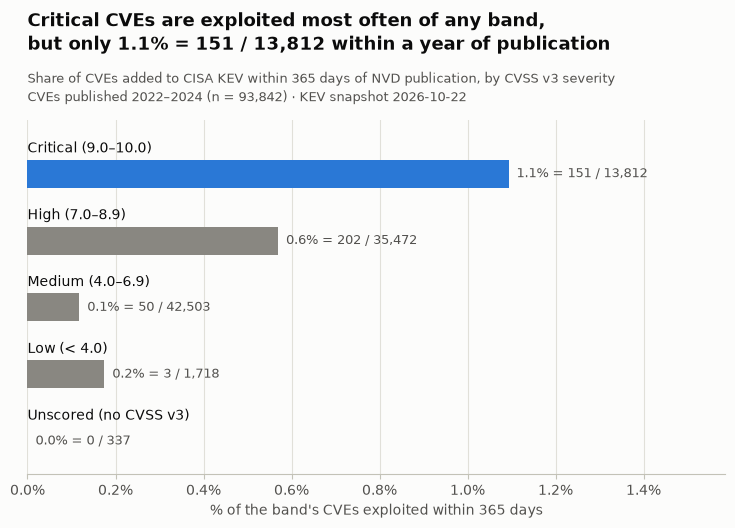

In [4]:
rows = q1.loc[SEVERITY_ORDER]
rates = rows["exploited"] / rows["cves"]
# The title claims that Critical has the highest exploited share of all bands.
assert (rates.drop("Critical") < rates["Critical"]).all(), "Critical is not the most exploited band"
title = (
    "Critical CVEs are exploited most often of any band,\n"
    f"but only {rows.loc['Critical', 'exploited_pct']} within a year of publication"
)
subtitle = (
    "Share of CVEs added to CISA KEV within 365 days of NVD publication, by CVSS v3 severity\n"
    f"CVEs published {first_day.year}–{last_day.year} (n = {N_CVES:,}) · KEV snapshot {KEV_SNAPSHOT}"
)

fig, ax = plt.subplots(figsize=(9, 4.6))
positions = list(range(len(rows)))
ax.barh(positions, rates, height=0.42, color=[BLUE if name == "Critical" else GRAY for name in rows.index])
for position, name, rate, label in zip(positions, rows.index, rates, rows["exploited_pct"]):
    ax.text(0, position - 0.27, SEVERITY_LABELS[name], ha="left", va="bottom", fontsize=10, color=INK)
    ax.text(rate, position, f"  {label}", ha="left", va="center", fontsize=9.5, color=INK_SECONDARY)
ax.set_ylim(len(rows) - 0.5, -0.8)  # Critical on top, with room for its label
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, rates.max() * 1.45)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
ax.set_xlabel("% of the band's CVEs exploited within 365 days")
add_titles(ax, title, subtitle)
save_figure(fig, "q1_exploitation_by_severity.png")
plt.show()

**Conclusion.** Exploitation within a year is rare in every band: 1.1% = 151 / 13,812 of Critical CVEs, 0.6% = 202 / 35,472 of High, 0.1% = 50 / 42,503 of Medium, 0.2% = 3 / 1,718 of Low and 0.0% = 0 / 337 of Unscored. Critical CVEs are exploited about twice as often as High ones, and the share falls with severity down to Medium (the Low share rests on only 3 CVEs). Still, 98.9% = 13,661 / 13,812 of Critical CVEs were not exploited within a year, so a Critical score on its own says little about which CVEs will be exploited.

## 2. Patching load vs coverage by CVSS threshold

Each rule is *patch every CVE with CVSS ≥ threshold*. **Load** is the share of all CVEs that the rule patches and **coverage** is the share of the exploited CVEs that it patches. Unscored CVEs are never patched by a CVSS rule, but they still count in both totals.

In [5]:
HIGH = 7.0  # CVSS >= 7 is High or Critical


def load_vs_coverage(flag: str) -> pd.DataFrame:
    """Load (share of all CVEs patched) and coverage (share of exploited CVEs patched) per CVSS threshold."""
    assert flag in EXPLOITED_FLAGS, f"unknown exploitation column: {flag}"
    # Unscored CVEs have a NULL score, so no threshold patches them; they still count in cves and exploited.
    table = query(f"""
        WITH thresholds AS (SELECT unnest($thresholds) AS threshold)
        SELECT t.threshold,
               count(*) FILTER (WHERE c.cvss_score >= t.threshold) AS patched,
               count(*) FILTER (WHERE c.cvss_score >= t.threshold AND c.{flag}) AS covered,
               count(*) AS cves,
               count(*) FILTER (WHERE c.{flag}) AS exploited
        FROM thresholds AS t
        CROSS JOIN cves AS c
        GROUP BY t.threshold
        ORDER BY t.threshold DESC
    """, {"thresholds": THRESHOLDS}).set_index("threshold")

    assert table.index.tolist() == THRESHOLDS, "thresholds missing or out of order"
    assert table["cves"].nunique() == 1 and table["exploited"].nunique() == 1, "the totals differ between thresholds"
    # A lower threshold patches a superset of CVEs, so load and coverage can only grow.
    assert table["patched"].is_monotonic_increasing, "load drops when the threshold goes down"
    assert table["covered"].is_monotonic_increasing, "coverage drops when the threshold goes down"
    assert (table["covered"] <= table["patched"]).all() and (table["patched"] <= table["cves"]).all()

    table["load"] = table["patched"] / table["cves"]
    table["coverage"] = table["covered"] / table["exploited"]
    table["load_pct"] = [pct(int(part), int(whole)) for part, whole in zip(table["patched"], table["cves"])]
    table["coverage_pct"] = [pct(int(part), int(whole)) for part, whole in zip(table["covered"], table["exploited"])]
    return table


def exploited_by_score(flag: str, threshold: float = HIGH) -> pd.Series:
    """Exploited CVEs split into CVSS < threshold, CVSS >= threshold and Unscored."""
    assert flag in EXPLOITED_FLAGS, f"unknown exploitation column: {flag}"
    split = query(f"""
        SELECT count(*) AS exploited,
               count(*) FILTER (WHERE cvss_score < $threshold) AS below,
               count(*) FILTER (WHERE cvss_score >= $threshold) AS at_or_above,
               count(*) FILTER (WHERE cvss_score IS NULL) AS unscored
        FROM cves
        WHERE {flag}
    """, {"threshold": threshold}).iloc[0]
    assert split["below"] + split["at_or_above"] + split["unscored"] == split["exploited"], "the split does not add up"
    return split


q2 = load_vs_coverage("exploited_365d")
q2_split = exploited_by_score("exploited_365d")

# Cross-check with question 1: thresholds 9, 7 and 4 are the lower limits of the severity bands.
bands = {9.0: ["Critical"], 7.0: ["Critical", "High"], 4.0: ["Critical", "High", "Medium"]}
for threshold, names in bands.items():
    assert q2.loc[threshold, "patched"] == q1.loc[names, "cves"].sum(), f"CVSS >= {threshold}: patched differs from question 1"
    assert q2.loc[threshold, "covered"] == q1.loc[names, "exploited"].sum(), f"CVSS >= {threshold}: covered differs from question 1"
assert q2_split["below"] == q1.loc[["Medium", "Low"], "exploited"].sum(), "CVSS < 7 differs from question 1"
assert q2_split["at_or_above"] == q2.loc[HIGH, "covered"], "CVSS >= 7 differs from the coverage table"

total_exploited = int(q2_split["exploited"])
print(f"Exploited = {EXPLOITED_FLAGS['exploited_365d']}")
print(f"  with CVSS < {HIGH:g}:          {pct(int(q2_split['below']), total_exploited)}")
print(f"  with CVSS >= {HIGH:g}:         {pct(int(q2_split['at_or_above']), total_exploited)}")
print(f"  Unscored (no CVSS v3): {pct(int(q2_split['unscored']), total_exploited)}")
q2[["load_pct", "coverage_pct"]].rename(
    index=lambda threshold: f"CVSS ≥ {threshold:g}",
    columns={"load_pct": "load: patched / all CVEs", "coverage_pct": "coverage: patched / exploited CVEs"},
)

Exploited = exploited within 365 days
  with CVSS < 7:          13.1% = 53 / 406
  with CVSS >= 7:         86.9% = 353 / 406
  Unscored (no CVSS v3): 0.0% = 0 / 406


,load: patched / all CVEs,coverage: patched / exploited CVEs
threshold,,
CVSS ≥ 9,"14.7% = 13,812 / 93,842",37.2% = 151 / 406
CVSS ≥ 8,"27.4% = 25,674 / 93,842",55.9% = 227 / 406
CVSS ≥ 7,"52.5% = 49,284 / 93,842",86.9% = 353 / 406
CVSS ≥ 6,"68.8% = 64,566 / 93,842",92.6% = 376 / 406
CVSS ≥ 5,"89.3% = 83,811 / 93,842",98.8% = 401 / 406
CVSS ≥ 4,"97.8% = 91,787 / 93,842",99.3% = 403 / 406


SKIPPED: reports\figures\q2_load_vs_coverage.png exists (set OVERWRITE_FIGURES = True to redraw)


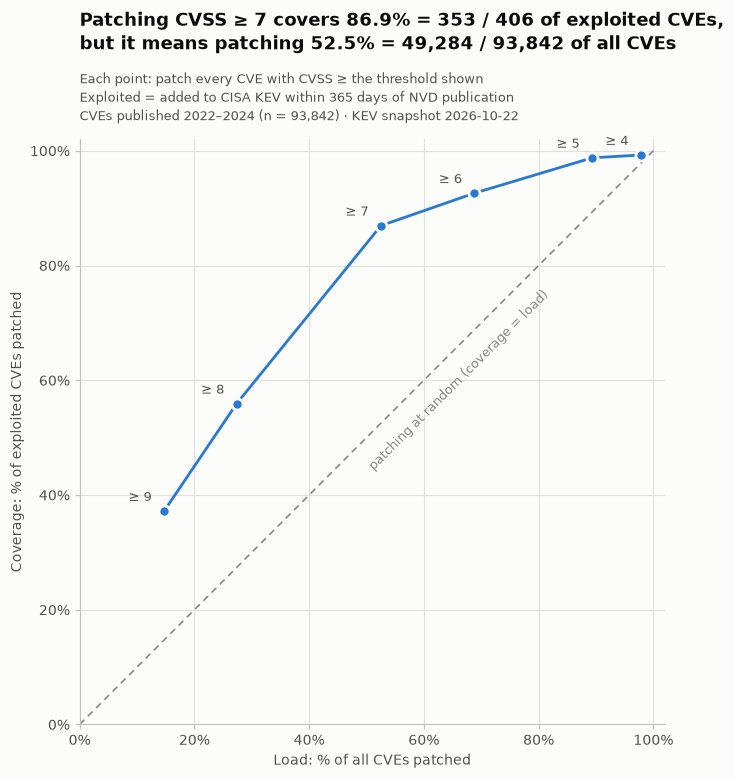

In [6]:
def plot_load_vs_coverage(series: list[tuple[pd.DataFrame, str, str]], title: str, subtitle: str, file_name: str) -> None:
    """Coverage against load, one point per CVSS threshold; series = [(table, legend label, colour), ...]."""
    fig, ax = plt.subplots(figsize=(8, 7.6))
    ax.plot([0, 1], [0, 1], color=GRAY, linewidth=1.2, linestyle=(0, (4, 3)))
    ax.text(0.66, 0.6, "patching at random (coverage = load)", rotation=45, rotation_mode="anchor",
            ha="center", va="center", fontsize=9, color=GRAY)
    for table, label, color in series:
        ax.plot(table["load"], table["coverage"], color=color, linewidth=2, marker="o", markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=2, solid_joinstyle="round", label=label)
    # Threshold labels go up and to the left of each point, the side away from the curve and the diagonal.
    for threshold, row in series[0][0].iterrows():
        ax.annotate(f"≥ {threshold:g}", xy=(row["load"], row["coverage"]), xytext=(-9, 5),
                    textcoords="offset points", ha="right", va="bottom", fontsize=9.5, color=INK_SECONDARY)
    if len(series) > 1:
        ax.legend(frameon=False, loc="lower right")
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.02)
    ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.set_xlabel("Load: % of all CVEs patched")
    ax.set_ylabel("Coverage: % of exploited CVEs patched")
    add_titles(ax, title, subtitle)
    save_figure(fig, file_name)
    plt.show()


at_high = q2.loc[HIGH]
# The title reads the curve as better than random: every threshold must cover more than it patches.
assert (q2["coverage"] > q2["load"]).all(), "some threshold does no better than patching at random"
title = (
    f"Patching CVSS ≥ {HIGH:g} covers {at_high['coverage_pct']} of exploited CVEs,\n"
    f"but it means patching {at_high['load_pct']} of all CVEs"
)
subtitle = (
    "Each point: patch every CVE with CVSS ≥ the threshold shown\n"
    "Exploited = added to CISA KEV within 365 days of NVD publication\n"
    f"CVEs published {first_day.year}–{last_day.year} (n = {N_CVES:,}) · KEV snapshot {KEV_SNAPSHOT}"
)
plot_load_vs_coverage([(q2, EXPLOITED_FLAGS["exploited_365d"], BLUE)], title, subtitle, "q2_load_vs_coverage.png")

**Conclusion.** Every CVSS threshold does better than patching at random, but coverage only gets high when the load is heavy. The usual CVSS ≥ 7 rule covers 86.9% = 353 / 406 of exploited CVEs while patching 52.5% = 49,284 / 93,842 of all CVEs; patching only CVSS ≥ 9 cuts the load to 14.7% = 13,812 / 93,842 but covers just 37.2% = 151 / 406. 53 exploited CVEs (13.1% = 53 / 406) have CVSS < 7 and none is Unscored; catching almost all of them with CVSS ≥ 5 (98.8% = 401 / 406) means patching 89.3% = 83,811 / 93,842 of all CVEs.

## 3. Who gets exploited, ransomware use and time to KEV

Population: the CVEs exploited within 365 days (main metric). Vendor and product are KEV's `vendorProject` and `product`, not normalized, and the top 10 keeps ties at the cut-off. `days_to_kev` is KEV's `dateAdded` minus the NVD publication day; values ≤ 0 (listed on or before publication) are kept and counted apart.

In [7]:
TOP_N = 10
N_EXPLOITED = int(universe["exploited_365d"])  # population of question 3


def top_exploited(columns: list[str]) -> pd.DataFrame:
    """Vendors, or vendor + product pairs, with the most exploited CVEs; ties at the cut-off are kept."""
    assert columns in (["vendor"], ["vendor", "product"]), f"unexpected grouping: {columns}"
    group = ", ".join(columns)
    table = query(f"""
        SELECT {group},
               count(*) AS exploited,
               rank() OVER (ORDER BY count(*) DESC) AS place
        FROM cves
        WHERE exploited_365d
        GROUP BY {group}
        QUALIFY place <= $top
        ORDER BY place, {group}
    """, {"top": TOP_N})
    assert len(table) >= TOP_N and table["place"].max() <= TOP_N, "the top table has the wrong size"
    assert table["exploited"].is_monotonic_decreasing, "the top table is not sorted by exploited CVEs"
    table["share_pct"] = [pct(int(n), N_EXPLOITED) for n in table["exploited"]]
    return table.set_index("place")


n_vendors = int(query("SELECT count(DISTINCT vendor) AS vendors FROM cves WHERE exploited_365d").iloc[0]["vendors"])
print(f"Vendors with exploited CVEs: {n_vendors}")
top_vendors = top_exploited(["vendor"])
top_vendors

Vendors with exploited CVEs: 96


,vendor,exploited,share_pct
place,,,
1,Microsoft,80,19.7% = 80 / 406
2,Apple,35,8.6% = 35 / 406
3,Google,26,6.4% = 26 / 406
4,Cisco,15,3.7% = 15 / 406
5,Ivanti,13,3.2% = 13 / 406
6,Adobe,11,2.7% = 11 / 406
6,Apache,11,2.7% = 11 / 406
8,VMware,10,2.5% = 10 / 406
9,Fortinet,9,2.2% = 9 / 406


In [8]:
top_products = top_exploited(["vendor", "product"])
top_products

,vendor,product,exploited,share_pct
place,,,,
1,Microsoft,Windows,49,12.1% = 49 / 406
2,Apple,Multiple Products,22,5.4% = 22 / 406
3,Google,Chromium V8,14,3.4% = 14 / 406
4,Linux,Kernel,9,2.2% = 9 / 406
5,Synacor,Zimbra Collaboration Suite (ZCS),8,2.0% = 8 / 406
6,Adobe,ColdFusion,7,1.7% = 7 / 406
7,Cisco,"Small Business RV160, RV260, RV340, and RV345 ...",5,1.2% = 5 / 406
7,Juniper,Junos OS,5,1.2% = 5 / 406
7,Palo Alto Networks,PAN-OS,5,1.2% = 5 / 406


In [9]:
kev_fields = query("""
    SELECT count(*) AS exploited,
           count(*) FILTER (WHERE ransomware) AS ransomware_known,
           count(*) FILTER (WHERE ransomware IS NULL OR vendor IS NULL OR product IS NULL) AS missing
    FROM cves
    WHERE exploited_365d
""").iloc[0]
assert int(kev_fields["exploited"]) == N_EXPLOITED, "the question 3 population differs from the universe count"
assert int(kev_fields["missing"]) == 0, "exploited CVEs without ransomware, vendor or product"
print(f"Known ransomware campaign use: {pct(int(kev_fields['ransomware_known']), N_EXPLOITED)}")

days = query("""
    SELECT count(*) FILTER (WHERE days_to_kev < 0) AS before_publication,
           count(*) FILTER (WHERE days_to_kev = 0) AS same_day,
           count(*) FILTER (WHERE days_to_kev > 0) AS after_publication,
           min(days_to_kev) AS min_days,
           quantile_cont(days_to_kev, 0.25) AS q1_days,
           median(days_to_kev) AS median_days,
           quantile_cont(days_to_kev, 0.75) AS q3_days,
           max(days_to_kev) AS max_days
    FROM cves
    WHERE exploited_365d
""").iloc[0]
# DuckDB and pandas must agree on the median and quartiles (both interpolate linearly).
raw_days = query("SELECT days_to_kev FROM cves WHERE exploited_365d")["days_to_kev"]
for quantile, column in ((0.25, "q1_days"), (0.5, "median_days"), (0.75, "q3_days")):
    assert abs(raw_days.quantile(quantile) - days[column]) < 1e-9, f"{column}: DuckDB and pandas disagree"
assert days["before_publication"] + days["same_day"] + days["after_publication"] == N_EXPLOITED, "days do not add up"
assert days["max_days"] <= EXPLOITED_WINDOW.days, "an exploited_365d CVE has days_to_kev above 365"

print("days_to_kev = KEV dateAdded - NVD published day")
print(f"  < 0 (in KEV before NVD publication): {pct(int(days['before_publication']), N_EXPLOITED)}")
print(f"  = 0 (same day):                      {pct(int(days['same_day']), N_EXPLOITED)}")
print(f"  > 0 (after publication):             {pct(int(days['after_publication']), N_EXPLOITED)}")
print(
    f"  min {days['min_days']:g} · Q1 {days['q1_days']:g} · median {days['median_days']:g}"
    f" · Q3 {days['q3_days']:g} · max {days['max_days']:g}"
)

DAY_BUCKETS = ["< 0", "0", "1–7", "8–30", "31–90", "91–180", "181–365"]
buckets = query("""
    SELECT CASE
               WHEN days_to_kev < 0 THEN '< 0'
               WHEN days_to_kev = 0 THEN '0'
               WHEN days_to_kev <= 7 THEN '1–7'
               WHEN days_to_kev <= 30 THEN '8–30'
               WHEN days_to_kev <= 90 THEN '31–90'
               WHEN days_to_kev <= 180 THEN '91–180'
               ELSE '181–365'
           END AS bucket,
           count(*) AS exploited
    FROM cves
    WHERE exploited_365d
    GROUP BY bucket
""").set_index("bucket")
assert set(buckets.index) <= set(DAY_BUCKETS), f"unexpected buckets: {sorted(buckets.index)}"
buckets = buckets.reindex(DAY_BUCKETS, fill_value=0)
assert buckets["exploited"].sum() == N_EXPLOITED, "the buckets do not add up to the exploited CVEs"
assert buckets.loc["< 0", "exploited"] == days["before_publication"], "bucket < 0 differs from the count"
assert buckets.loc["0", "exploited"] == days["same_day"], "bucket 0 differs from the count"
buckets["share_pct"] = [pct(int(n), N_EXPLOITED) for n in buckets["exploited"]]
buckets

Known ransomware campaign use: 25.4% = 103 / 406
days_to_kev = KEV dateAdded - NVD published day
  < 0 (in KEV before NVD publication): 12.8% = 52 / 406
  = 0 (same day):                      18.0% = 73 / 406
  > 0 (after publication):             69.2% = 281 / 406
  min -290 · Q1 0 · median 6 · Q3 64 · max 359


,exploited,share_pct
bucket,,
< 0,52,12.8% = 52 / 406
0,73,18.0% = 73 / 406
1–7,91,22.4% = 91 / 406
8–30,54,13.3% = 54 / 406
31–90,49,12.1% = 49 / 406
91–180,46,11.3% = 46 / 406
181–365,41,10.1% = 41 / 406


Saved reports\figures\q3_days_to_kev.png

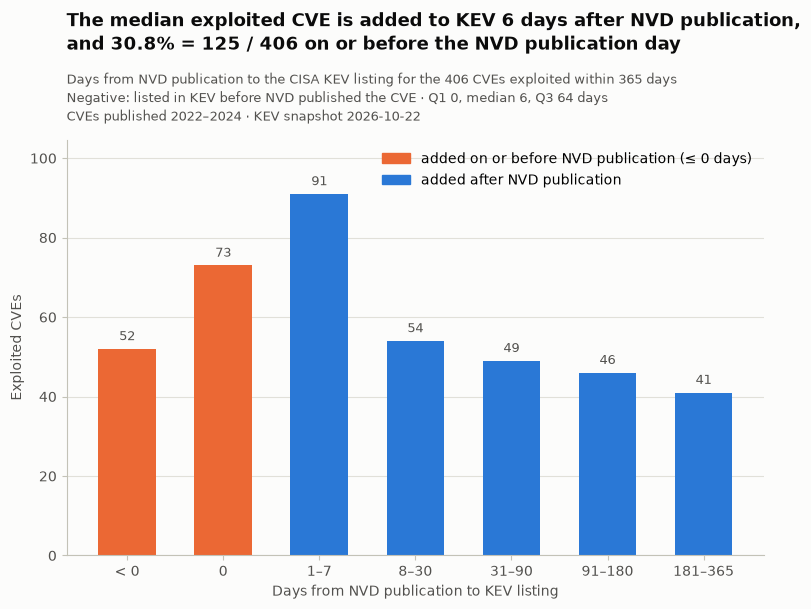

In [10]:
on_or_before = int(days["before_publication"] + days["same_day"])
title = (
    f"The median exploited CVE is added to KEV {days['median_days']:g} days after NVD publication,\n"
    f"and {pct(on_or_before, N_EXPLOITED)} on or before the NVD publication day"
)
subtitle = (
    f"Days from NVD publication to the CISA KEV listing for the {N_EXPLOITED} CVEs exploited within 365 days\n"
    f"Negative: listed in KEV before NVD published the CVE · Q1 {days['q1_days']:g},"
    f" median {days['median_days']:g}, Q3 {days['q3_days']:g} days\n"
    f"CVEs published {first_day.year}–{last_day.year} · KEV snapshot {KEV_SNAPSHOT}"
)

fig, ax = plt.subplots(figsize=(9, 5.4))
positions = list(range(len(DAY_BUCKETS)))
listed_early = [bucket in ("< 0", "0") for bucket in DAY_BUCKETS]
ax.bar(positions, buckets["exploited"], width=0.6, color=[ORANGE if early else BLUE for early in listed_early])
for position, count in zip(positions, buckets["exploited"]):
    ax.annotate(f"{count:,}", xy=(position, count), xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontsize=9.5, color=INK_SECONDARY)
ax.set_xticks(positions, DAY_BUCKETS)
ax.set_ylim(0, buckets["exploited"].max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Days from NVD publication to KEV listing")
ax.set_ylabel("Exploited CVEs")
ax.legend(
    handles=[
        Patch(color=ORANGE, label="added on or before NVD publication (≤ 0 days)"),
        Patch(color=BLUE, label="added after NVD publication"),
    ],
    frameon=False,
    loc="upper right",
)
add_titles(ax, title, subtitle)
save_figure(fig, "q3_days_to_kev.png")
plt.show()

**Conclusion.** Exploited CVEs are concentrated in a few vendors: of the 406, Microsoft has 19.7% = 80 / 406 (Windows 12.1% = 49 / 406), Apple 8.6% = 35 / 406 and Google 6.4% = 26 / 406, out of 96 vendors; these are shares of the exploited CVEs, not exploitation rates, because vendor and product come from KEV and are unknown for CVEs outside it. 25.4% = 103 / 406 of the exploited CVEs have known ransomware campaign use. The median exploited CVE was added to KEV 6 days after its NVD publication date, and 30.8% = 125 / 406 were added on or before that date (52 before, 73 the same day).

## 4. Sensitivity check: exploited = in KEV at any time

Questions 1 and 2 again, now counting as exploited every CVE in the KEV snapshot, including those added more than 365 days after NVD publication. The CVE counts and the load do not depend on exploitation, so only the exploited counts and the coverage can change.

In [11]:
q1_any = exploited_by_severity("in_kev")
# CVEs in KEV that were added more than 365 days after publication: the only difference between both definitions.
late = query("""
    SELECT severity, count(*) AS late
    FROM cves
    WHERE in_kev AND NOT exploited_365d
    GROUP BY severity
""").set_index("severity")["late"].reindex(SEVERITY_ORDER, fill_value=0)

assert (q1_any["cves"] == q1["cves"]).all(), "the CVE counts must not depend on the exploitation definition"
assert (q1_any["exploited"] >= q1["exploited"]).all(), "a band has fewer CVEs in KEV at any time than within 365 days"
added_after = q1_any.loc[SEVERITY_ORDER, "exploited"] - q1.loc[SEVERITY_ORDER, "exploited"]
assert (added_after == late).all(), "the late additions per band do not match"
n_late = int(late.sum())
assert n_late == int(universe["in_kev"]) - int(universe["exploited_365d"]), "the late additions do not add up"


def band_order(table: pd.DataFrame) -> list[str]:
    """Severity bands from the highest to the lowest exploited share (ties keep SEVERITY_ORDER)."""
    rates = table.loc[SEVERITY_ORDER, "exploited"] / table.loc[SEVERITY_ORDER, "cves"]
    return rates.sort_values(ascending=False, kind="stable").index.tolist()


print(f"Added to KEV more than 365 days after publication: {n_late:,}")
print(f"Bands by exploited share, {EXPLOITED_FLAGS['exploited_365d']}: {' > '.join(band_order(q1))}")
print(f"Bands by exploited share, {EXPLOITED_FLAGS['in_kev']}: {' > '.join(band_order(q1_any))}")
pd.DataFrame({
    "cves": q1["cves"],
    EXPLOITED_FLAGS["exploited_365d"]: q1["exploited_pct"],
    EXPLOITED_FLAGS["in_kev"]: q1_any["exploited_pct"],
    "added after 365 days": q1_any["exploited"] - q1["exploited"],
}).rename(index=SEVERITY_LABELS)

Added to KEV more than 365 days after publication: 51
Bands by exploited share, exploited within 365 days: Critical > High > Low > Medium > Unscored
Bands by exploited share, in KEV at any time: Critical > High > Low > Medium > Unscored


,cves,exploited within 365 days,in KEV at any time,added after 365 days
Critical (9.0–10.0),13812,"1.1% = 151 / 13,812","1.2% = 167 / 13,812",16
High (7.0–8.9),35472,"0.6% = 202 / 35,472","0.7% = 234 / 35,472",32
Medium (4.0–6.9),42503,"0.1% = 50 / 42,503","0.1% = 53 / 42,503",3
Low (< 4.0),1718,"0.2% = 3 / 1,718","0.2% = 3 / 1,718",0
Unscored (no CVSS v3),337,0.0% = 0 / 337,0.0% = 0 / 337,0
Total,93842,"0.4% = 406 / 93,842","0.5% = 457 / 93,842",51


In [12]:
q2_any = load_vs_coverage("in_kev")
q2_any_split = exploited_by_score("in_kev")
late_split = q2_any_split - q2_split  # exploited_365d is a subset of in_kev, so this is the late additions

assert (q2_any["patched"] == q2["patched"]).all(), "the load must not depend on the exploitation definition"
assert (q2_any["covered"] >= q2["covered"]).all(), "coverage lost CVEs when counting KEV at any time"
assert int(late_split["exploited"]) == n_late, "the late additions differ between questions 1 and 2"

n_365 = int(q2_split["exploited"])
n_any = int(q2_any_split["exploited"])
print(f"Added to KEV more than 365 days after publication: {n_late:,}")
print(f"  with CVSS >= {HIGH:g}:         {pct(int(late_split['at_or_above']), n_late)}")
print(f"  with CVSS < {HIGH:g}:          {pct(int(late_split['below']), n_late)}")
print(f"  Unscored (no CVSS v3): {pct(int(late_split['unscored']), n_late)}")
print(f"Exploited with CVSS < {HIGH:g}, {EXPLOITED_FLAGS['exploited_365d']}: {pct(int(q2_split['below']), n_365)}")
print(f"Exploited with CVSS < {HIGH:g}, {EXPLOITED_FLAGS['in_kev']}: {pct(int(q2_any_split['below']), n_any)}")
pd.DataFrame({
    "load: patched / all CVEs": q2["load_pct"],
    f"coverage, {EXPLOITED_FLAGS['exploited_365d']}": q2["coverage_pct"],
    f"coverage, {EXPLOITED_FLAGS['in_kev']}": q2_any["coverage_pct"],
}).rename(index=lambda threshold: f"CVSS ≥ {threshold:g}")

Added to KEV more than 365 days after publication: 51
  with CVSS >= 7:         94.1% = 48 / 51
  with CVSS < 7:          5.9% = 3 / 51
  Unscored (no CVSS v3): 0.0% = 0 / 51
Exploited with CVSS < 7, exploited within 365 days: 13.1% = 53 / 406
Exploited with CVSS < 7, in KEV at any time: 12.3% = 56 / 457


,load: patched / all CVEs,"coverage, exploited within 365 days","coverage, in KEV at any time"
threshold,,,
CVSS ≥ 9,"14.7% = 13,812 / 93,842",37.2% = 151 / 406,36.5% = 167 / 457
CVSS ≥ 8,"27.4% = 25,674 / 93,842",55.9% = 227 / 406,55.1% = 252 / 457
CVSS ≥ 7,"52.5% = 49,284 / 93,842",86.9% = 353 / 406,87.7% = 401 / 457
CVSS ≥ 6,"68.8% = 64,566 / 93,842",92.6% = 376 / 406,93.2% = 426 / 457
CVSS ≥ 5,"89.3% = 83,811 / 93,842",98.8% = 401 / 406,98.7% = 451 / 457
CVSS ≥ 4,"97.8% = 91,787 / 93,842",99.3% = 403 / 406,99.3% = 454 / 457


SKIPPED: reports\figures\q4_sensitivity_load_vs_coverage.png exists (set OVERWRITE_FIGURES = True to redraw)


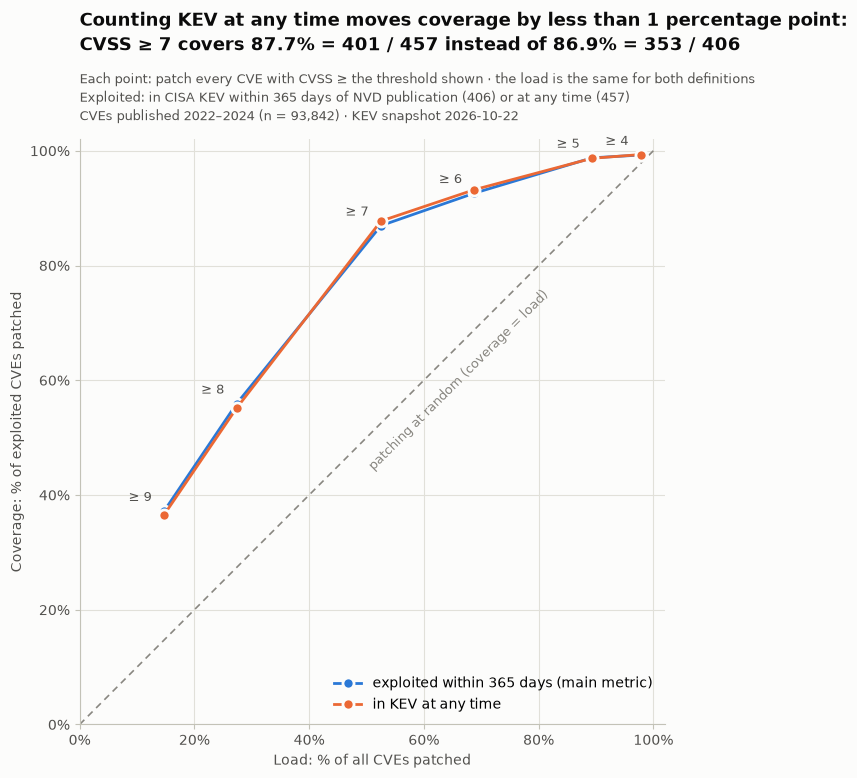

In [13]:
coverage_shift = (q2_any["coverage"] - q2["coverage"]).abs().max()
# The title and the conclusion claim that coverage moves by less than one percentage point at every
# threshold and that the severity bands keep their order.
assert coverage_shift < 0.01, f"coverage moves by {coverage_shift:.4f} at some threshold"
assert band_order(q1_any) == band_order(q1), "the severity bands change order"
at_high_any = q2_any.loc[HIGH]
title = (
    "Counting KEV at any time moves coverage by less than 1 percentage point:\n"
    f"CVSS ≥ {HIGH:g} covers {at_high_any['coverage_pct']} instead of {at_high['coverage_pct']}"
)
subtitle = (
    "Each point: patch every CVE with CVSS ≥ the threshold shown · the load is the same for both definitions\n"
    f"Exploited: in CISA KEV within 365 days of NVD publication ({n_365}) or at any time ({n_any})\n"
    f"CVEs published {first_day.year}–{last_day.year} (n = {N_CVES:,}) · KEV snapshot {KEV_SNAPSHOT}"
)
plot_load_vs_coverage(
    [
        (q2, f"{EXPLOITED_FLAGS['exploited_365d']} (main metric)", BLUE),
        (q2_any, EXPLOITED_FLAGS["in_kev"], ORANGE),
    ],
    title,
    subtitle,
    "q4_sensitivity_load_vs_coverage.png",
)

**Conclusion.** The conclusions do not change. Counting every CVE in the KEV snapshot (457 exploited instead of 406), the severity bands keep the same order (Critical > High > Low > Medium > Unscored) and coverage moves by less than one percentage point at every threshold: CVSS ≥ 7 covers 87.7% = 401 / 457 instead of 86.9% = 353 / 406, and 12.3% = 56 / 457 of the exploited CVEs still have CVSS < 7. The reason is that the 51 late additions are few and score like the early ones, even more concentrated in High (94.1% = 48 / 51 with CVSS ≥ 7: 16 Critical, 32 High, 3 Medium), so they lift coverage slightly at CVSS ≥ 7 and lower it slightly at CVSS ≥ 9.

In [14]:
n_exploited = int(q1.loc["Total", "exploited"])
print("Summary")
print(f"  CVEs:                      {N_CVES:,}")
print(f"  Unscored:                  {pct(int(universe['unscored']), N_CVES)}")
print(f"  Exploited within 365 days: {pct(n_exploited, N_CVES)}")
print(f"    with CVSS < {HIGH:g}:          {pct(int(q2_split['below']), n_exploited)}")
print(f"    known ransomware use:    {pct(int(kev_fields['ransomware_known']), n_exploited)}")
print(f"    days_to_kev <= 0:        {pct(on_or_before, n_exploited)} (median {days['median_days']:g} days)")
print(f"  In KEV at any time:        {pct(n_any, N_CVES)}")
print(f"    with CVSS < {HIGH:g}:          {pct(int(q2_any_split['below']), n_any)}")
print(f"    added after 365 days:    {pct(n_late, n_any)}")
for file_name, status in figure_status.items():
    print(f"  Figure {status}: {file_name}")

assert n_exploited == int(universe["exploited_365d"]), "question 1 and the universe disagree on exploited CVEs"
assert n_exploited == int(q2_split["exploited"]) == int(q2["exploited"].iloc[0]), "question 2 disagrees on exploited CVEs"
assert n_exploited == N_EXPLOITED == int(buckets["exploited"].sum()), "question 3 disagrees on exploited CVEs"
assert n_any == int(universe["in_kev"]) == int(q1_any.loc["Total", "exploited"]), "question 4 disagrees on KEV CVEs"
missing = [name for name in figure_status if not (FIGURES_DIR / name).exists()]
assert not missing, f"figures not found in {FIGURES_DIR}: {missing}"
connection.close()
print("All checks passed.")

Summary
  CVEs:                      93,842
  Unscored:                  0.4% = 337 / 93,842
  Exploited within 365 days: 0.4% = 406 / 93,842
    with CVSS < 7:          13.1% = 53 / 406
    known ransomware use:    25.4% = 103 / 406
    days_to_kev <= 0:        30.8% = 125 / 406 (median 6 days)
  In KEV at any time:        0.5% = 457 / 93,842
    with CVSS < 7:          12.3% = 56 / 457
    added after 365 days:    11.2% = 51 / 457
  Figure skipped: q1_exploitation_by_severity.png
  Figure skipped: q2_load_vs_coverage.png
  Figure saved: q3_days_to_kev.png
  Figure skipped: q4_sensitivity_load_vs_coverage.png
All checks passed.
